# CDP simulation — GPU (CuPy) version

Same physics, solver and sweeps as `CDP_Simulation_v8.1_real_setup.ipynb`, adapted to run on a CUDA GPU such as Colab's T4:

- all large arrays (fields, FFTs, masks, the sparse detector matrix) live on the GPU through CuPy (`xp` in the code);
- random numbers (masks, noise, start vectors) are still drawn on the CPU, so results are identical for the same seed;
- results are brought back to NumPy (`to_cpu`) for metrics and plots;
- the sweeps run one simulation at a time (the GPU does the parallel work).

**On Colab:** Runtime → Change runtime type → *T4 GPU*, then Runtime → Run all. Without a GPU the notebook falls back to NumPy on the CPU.

In [ ]:
# GPU version for Google Colab: Runtime > Change runtime type > T4 GPU, then run all cells.
# CuPy is preinstalled on Colab's GPU runtimes. Without a GPU the notebook runs on the CPU with NumPy.
!nvidia-smi -L || echo "no NVIDIA GPU visible: the notebook will run on the CPU"

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
import math
import multiprocessing
from scipy.ndimage import map_coordinates
import scipy.sparse as sp

# Heavy arrays live in `xp`: CuPy when a CUDA GPU is available (Colab: Runtime > Change
# runtime type > T4 GPU), NumPy otherwise. to_cpu() brings results back for metrics and plots.
try:
    import cupy as cp
    import cupyx.scipy.sparse as cpsp
    GPU = cp.cuda.runtime.getDeviceCount() > 0
except Exception:
    GPU = False

if GPU:
    xp = cp
    print("Running on GPU:", cp.cuda.runtime.getDeviceProperties(0)["name"].decode())
else:
    xp = np
    print("No GPU found: running on the CPU with NumPy")

fft2, ifft2 = xp.fft.fft2, xp.fft.ifft2

def to_cpu(a):
    """Return `a` as a NumPy array (a no-op on the CPU)."""
    return cp.asnumpy(a) if GPU and isinstance(a, cp.ndarray) else a

def cubic_kernel(t, a=-0.5):
    """Keys cubic interpolation kernel.

    Parameters
    ----------
    t : array_like
        Distance from the sample point in grid units; the kernel is zero for |t| >= 2.
    a : float
        Kernel parameter; -0.5 gives the standard Catmull-Rom-like cubic.
    """

    t = np.abs(t)

    return np.where(t <= 1, (a + 2) * t**3 - (a + 3) * t**2 + 1,
           np.where(t < 2, a * t**3 - 5 * a * t**2 + 8 * a * t - 4 * a, 0.0))

class SamplingOperator:
    """Linear map from the propagated field on the (upsampled) grid to the camera.

    Each camera pixel is sampled at ``subsamples x subsamples`` points spread over its
    area; the field at each point is obtained by cubic interpolation on the propagation
    grid, and the pixel reads the mean intensity of its points (see `intensity`). The
    camera may be shifted, rotated in its plane and tilted out of it. The mapping is
    stored as one sparse matrix, so `forward` and `adjoint` are single matrix products.
    """

    def __init__(self, n_prop, dx_prop, n_det, dx_det, shift_x=0.0, shift_y=0.0, rotation_deg=0.0, origin=None, tilt_x_deg=0.0, tilt_y_deg=0.0, subsamples=1, precision="double"):
        """
        Parameters
        ----------
        n_prop, dx_prop : int, float
            Size and pitch [m] of the grid the field is given on (Propagator.n_out, .dx_out).
        n_det, dx_det : int, float
            Camera pixels per side and pixel pitch [m].
        shift_x, shift_y : float
            Displacement of the camera centre from the optical axis [m].
        rotation_deg : float
            Rotation of the camera about its centre, counter-clockwise from x to y [deg].
        origin : float, optional
            Grid index of the optical axis (Propagator.origin_out); default n_prop / 2.
        tilt_x_deg, tilt_y_deg : float
            Out-of-plane tilt of the camera about its centre, about x then y [deg].
            Pixel positions are foreshortened and the intensity scaled by the obliquity;
            the change of each pixel's distance to the SLM is not modelled.
        subsamples : int
            Sample points per pixel side; the pixel reads their mean intensity.
        precision : {"double", "single"}
            Floating-point precision; single is ~1.5x faster and ample here.
        """

        self.n_prop = n_prop
        self.n_det = n_det
        self.n_sub = subsamples ** 2

        self.rdtype = np.float32 if precision == "single" else np.float64
        self.cdtype = np.complex64 if precision == "single" else np.complex128

        if origin is None:
            origin = n_prop / 2

        theta = np.deg2rad(rotation_deg)

        x_det = (np.arange(n_det) - n_det/2) * dx_det
        y_det = (np.arange(n_det) - n_det/2) * dx_det

        Xd, Yd = np.meshgrid(x_det, y_det, indexing="ij")

        # Sample points at the centres of equal sub-cells, in the camera's own
        # coordinates so they rotate and tilt with the pixel.
        o = ((np.arange(subsamples) + 0.5) / subsamples - 0.5) * dx_det
        offsets = [(ox, oy) for ox in o for oy in o]

        ct = np.cos(theta)
        st = np.sin(theta)

        tx, ty = np.deg2rad(tilt_x_deg), np.deg2rad(tilt_y_deg)
        cx, sx = np.cos(tx), np.sin(tx)
        cy, sy = np.cos(ty), np.sin(ty)

        # Power on a tilted pixel scales with cos(alpha) = cx*cy, the amplitude with its root.
        obliquity = np.sqrt(cx * cy)

        n_pix = n_det * n_det
        rows, cols, vals = [], [], []
        invalid = np.zeros((n_det, n_det), dtype=bool)

        for k, (ox, oy) in enumerate(offsets):

            # In-plane rotation, then tilt (projection onto the propagation plane), then shift.
            X_rot = ct*(Xd + ox) - st*(Yd + oy)
            Y_rot = st*(Xd + ox) + ct*(Yd + oy)

            Xp = X_rot*cy + Y_rot*sx*sy + shift_x
            Yp = Y_rot*cx + shift_y

            Ix = Xp/dx_prop + origin
            Iy = Yp/dx_prop + origin

            x0 = np.floor(Ix).astype(np.int64)
            y0 = np.floor(Iy).astype(np.int64)

            # Cubic interpolation needs the 4 x 4 surrounding grid points.
            valid = (x0 - 1 >= 0) & (x0 + 2 < n_prop) & (y0 - 1 >= 0) & (y0 + 2 < n_prop)
            invalid |= ~valid

            row = k * n_pix + np.arange(n_pix)

            for i in range(-1, 3):
                wx = cubic_kernel(Ix - (x0 + i))
                xi = np.clip(x0 + i, 0, n_prop - 1)

                for j in range(-1, 3):
                    wy = cubic_kernel(Iy - (y0 + j))
                    yj = np.clip(y0 + j, 0, n_prop - 1)

                    rows.append(row)
                    cols.append((xi * n_prop + yj).ravel())
                    vals.append((wx * wy * valid * obliquity).ravel())

        # A real camera would see light there, so pixels outside the grid are flagged.
        n_outside = np.count_nonzero(invalid)
        if n_outside > 0:
            print(f"WARNING: {n_outside} of {n_det**2} detector pixels lie outside "
                  f"the propagation grid and will read 0. Increase n_prop.")

        self.M = sp.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))),
                               shape=(self.n_sub * n_pix, n_prop * n_prop)).astype(self.rdtype)
        self.MT = self.M.T.tocsr()

        if GPU:
            # cuSPARSE needs the same type as the field it multiplies, so the real
            # weights are stored as complex numbers on the GPU.
            self.M = cpsp.csr_matrix(self.M.astype(self.cdtype))
            self.MT = cpsp.csr_matrix(self.MT.astype(self.cdtype))

    def forward(self, U):
        """Sample the field at every camera sample point.

        Parameters
        ----------
        U : array, shape (L, n_prop, n_prop)
            Field on the propagation grid, one slice per mask.

        Returns
        -------
        array, shape (L, n_sub, n_det, n_det)
            Complex field at each sample point of each pixel.
        """

        L = U.shape[0]
        U = U.astype(self.cdtype, copy=False)

        return (self.M @ xp.ascontiguousarray(U.reshape(L, -1).T)).T.reshape(L, self.n_sub, self.n_det, self.n_det)

    def adjoint(self, V):
        """Adjoint of `forward`: spread sample-point values back onto the grid.

        Parameters
        ----------
        V : array, shape (L, n_sub, n_det, n_det)

        Returns
        -------
        array, shape (L, n_prop, n_prop)
        """

        L = V.shape[0]
        V = V.astype(self.cdtype, copy=False)

        return (self.MT @ xp.ascontiguousarray(V.reshape(L, -1).T)).T.reshape(L, self.n_prop, self.n_prop)

    def intensity(self, V):
        """Pixel values: mean |field|^2 over each pixel's sample points.

        Parameters
        ----------
        V : array, shape (L, n_sub, n_det, n_det)

        Returns
        -------
        array, shape (L, n_det, n_det)
        """

        return xp.mean(xp.abs(V) ** 2, axis=1)

class Propagator:
    """Band-limited angular-spectrum propagation from the SLM to the camera plane.

    The SLM field (n_in x n_in) is zero-padded to an n x n grid so that light leaving the
    SLM aperture does not wrap around onto the camera. The transfer function includes the
    band limit of Matsushima & Shimobaba (2009) and the square-pixel envelope of the SLM.
    The output can be returned on a finer grid by zero-padding the spectrum, which gives
    the exact band-limited field between the SLM-pitch samples.
    """

    def __init__(self, n_in, n, dx, wavelength, z, fill_factor=1.0, upsample=1, precision="double"):
        """
        Parameters
        ----------
        n_in : int
            SLM grid size; the field is defined on n_in x n_in pixels.
        n : int
            Propagation grid size (n >= n_in), see `choose_prop_grid`.
        dx : float
            SLM pixel pitch [m].
        wavelength, z : float
            Wavelength and SLM-camera distance [m].
        fill_factor : float
            Active fraction of each SLM pixel's area (square aperture of side dx*sqrt(fill_factor)).
        upsample : int
            The propagated field is returned on a grid `upsample` times finer.
        precision : {"double", "single"}
            Floating-point precision; single is ~1.5x faster and ample here.
        """

        self.n_in = n_in
        self.n = n
        self.dx = dx
        self.wavelength = wavelength
        self.z = z
        self.fill_factor = fill_factor

        self.cdtype = np.complex64 if precision == "single" else np.complex128

        self.offset = (n - n_in) // 2
        # Grid index of the optical axis (SLM pixel i is at (i - n_in/2) * dx).
        self.origin = self.offset + n_in / 2

        self.m = upsample
        self.n_out = n * upsample
        self.dx_out = dx / upsample
        self.origin_out = self.origin * upsample
        # Numbers of non-negative / negative frequencies, for copying the spectrum
        # between the two grids with slices (much faster than fancy indexing).
        self.h = (n + 1) // 2
        self.k = n // 2

        fx = np.fft.fftfreq(n, d=dx)
        fy = np.fft.fftfreq(n, d=dx)
        FX, FY = np.meshgrid(fx, fy)

        term = (1 - (wavelength * FX) ** 2 - (wavelength * FY) ** 2)
        k = 2 * np.pi / wavelength

        # Band limit: drop frequencies where the transfer-function phase is undersampled.
        df = 1 / (n * dx)
        f_limit = 1 / (wavelength * np.sqrt((2 * df * z) ** 2 + 1))
        band = (np.abs(FX) <= f_limit) & (np.abs(FY) <= f_limit)

        # Square SLM pixels have the spectrum sinc(a fx) sinc(a fy). The main diffraction
        # order's amplitude scales with the aperture area (fill_factor); the rest of the
        # light goes into higher orders, which a grid of pitch dx cannot represent.
        a = dx * np.sqrt(fill_factor)
        pixel_envelope = np.sinc(a * FX) * np.sinc(a * FY)

        self.H = xp.asarray((np.exp(1j * k * z * np.sqrt(term.astype(complex))) * band * fill_factor * pixel_envelope).astype(self.cdtype))
        self.H_adj = xp.conj(self.H)

    def pad(self, U):
        """Embed the SLM-sized field U (..., n_in, n_in) in the centre of an n x n zero grid."""

        out = xp.zeros(U.shape[:-2] + (self.n, self.n), dtype=self.cdtype)
        out[..., self.offset:self.offset + self.n_in, self.offset:self.offset + self.n_in] = U

        return out

    def crop(self, V):
        """Cut the SLM region (..., n_in, n_in) out of an n x n grid; the adjoint of `pad`."""

        return V[..., self.offset:self.offset + self.n_in, self.offset:self.offset + self.n_in]

    def forward(self, U):
        """Propagate SLM fields to the camera plane.

        Parameters
        ----------
        U : array, shape (L, n_in, n_in)
            Field just after the SLM, one slice per mask.

        Returns
        -------
        array, shape (L, n_out, n_out)
            Field on the (upsampled) grid at distance z.
        """

        A = fft2(self.pad(U), axes=(-2,-1), norm="ortho") * self.H[None,:,:]

        if self.m == 1:
            return ifft2(A, axes=(-2,-1), norm="ortho")

        B = xp.zeros(A.shape[:-2] + (self.n_out, self.n_out), dtype=self.cdtype)
        n, N, h, k = self.n, self.n_out, self.h, self.k
        B[..., :h, :h] = A[..., :h, :h]
        B[..., :h, N-k:] = A[..., :h, n-k:]
        B[..., N-k:, :h] = A[..., n-k:, :h]
        B[..., N-k:, N-k:] = A[..., n-k:, n-k:]

        return ifft2(B, axes=(-2,-1), norm="ortho") * self.m

    def adjoint(self, V):
        """Adjoint of `forward`: back-propagate (L, n_out, n_out) fields to (L, n_in, n_in)."""

        A = fft2(V.astype(self.cdtype, copy=False), axes=(-2,-1), norm="ortho")

        if self.m > 1:
            B = A
            A = xp.empty(B.shape[:-2] + (self.n, self.n), dtype=self.cdtype)
            n, N, h, k = self.n, self.n_out, self.h, self.k
            A[..., :h, :h] = B[..., :h, :h]
            A[..., :h, n-k:] = B[..., :h, N-k:]
            A[..., n-k:, :h] = B[..., N-k:, :h]
            A[..., n-k:, n-k:] = B[..., N-k:, N-k:]
            A *= self.m

        return self.crop(ifft2(A * self.H_adj[None,:,:], axes=(-2,-1), norm="ortho"))

def choose_prop_grid(n_slm, dx_slm, n_det, dx_det, wavelength, z, shift_max=0.0, rotation_max_deg=0.0, margin=2.0):
    """Smallest power-of-two propagation grid size for the given geometry.

    The grid must contain the SLM and the (shifted, rotated) camera, be wide enough
    that light diffracted off the SLM edge cannot wrap around (FFT periodicity) onto
    the camera, and sample the transfer function (n >= wavelength z / dx^2).

    Parameters
    ----------
    n_slm, dx_slm : int, float
        SLM grid size and pitch [m].
    n_det, dx_det : int, float
        Camera pixels per side and pitch [m].
    wavelength, z : float
        Wavelength and SLM-camera distance [m].
    shift_max, rotation_max_deg : float
        Largest camera shift [m] and rotation [deg] the grid must accommodate.
    margin : float
        Safety factor on the required width.

    Returns
    -------
    int
    """

    slm_half = n_slm * dx_slm / 2

    theta = np.deg2rad(rotation_max_deg)
    det_half = n_det * dx_det / 2 * (abs(np.cos(theta)) + abs(np.sin(theta))) + shift_max

    # Largest transverse displacement of light diffracted by the SLM grid.
    s = wavelength / (2 * dx_slm)
    spread = z * s / np.sqrt(1 - s ** 2)

    width = margin * max(slm_half + spread + det_half, 2 * det_half, 2 * slm_half)
    n_min = max(width / dx_slm, wavelength * z / dx_slm ** 2)

    return int(2 ** np.ceil(np.log2(n_min)))

def define_sample(n, sigma, dx_slm, aberrations=None, R=None):
    """Gaussian beam on the SLM grid with optional low-order aberrations.

    Parameters
    ----------
    n, dx_slm : int, float
        SLM grid size and pitch [m].
    sigma : float
        Amplitude standard deviation of the Gaussian [m].
    aberrations : dict, optional
        Coefficients [rad] for any of "tilt_x", "tilt_y", "defocus", "astig_0",
        "astig_45", "coma_x", "coma_y", "spherical" (Zernike-like terms); missing = 0.
    R : float, optional
        Radius the aberration terms are normalised to; default half the SLM width.

    Returns
    -------
    numpy.ndarray, shape (n, n), complex
    """

    a = aberrations or {}
    if R is None:
        R = n * dx_slm / 2

    x = (np.arange(n) - n/2) * dx_slm
    y = (np.arange(n) - n/2) * dx_slm
    X, Y = np.meshgrid(x, y, indexing="ij")

    amplitude = np.exp(-(X ** 2 + Y ** 2) / (2 * sigma ** 2))

    u, v = X / R, Y / R
    r2 = u**2 + v**2

    phase = (a.get("tilt_x", 0)    * u
           + a.get("tilt_y", 0)    * v
           + a.get("defocus", 0)   * (2*r2 - 1)
           + a.get("astig_0", 0)   * (u**2 - v**2)
           + a.get("astig_45", 0)  * (2*u*v)
           + a.get("coma_x", 0)    * (3*r2 - 2) * u
           + a.get("coma_y", 0)    * (3*r2 - 2) * v
           + a.get("spherical", 0) * (6*r2**2 - 6*r2 + 1))

    return amplitude * np.exp(1j * phase)

def define_masks(L, n, rng):
    """Random SLM phase masks with 256 phase levels.

    Parameters
    ----------
    L, n : int
        Number of masks and SLM grid size.
    rng : numpy.random.Generator
        Source of randomness (seeded for reproducibility).

    Returns
    -------
    array, shape (L, n, n)
        exp(i phi) per pixel; drawn on the CPU, stored in `xp`.
    """

    i = rng.integers(0, 256, size=(L, n, n))
    phi = 2*np.pi * i / 256

    return xp.asarray(np.exp(1j * phi))

def effective_masks(D, eta, psi=0.0):
    """Masks including the light the SLM leaves unmodulated (zeroth order).

    Each pixel multiplies the beam by sqrt(1-eta) e^{-i phi} + sqrt(eta) e^{i psi}
    (the code applies conj(D)), so the zeroth order is simply part of the mask and the
    rest of the model is unchanged. Averaged over random masks, power is conserved.

    Parameters
    ----------
    D : array, shape (L, n, n)
        Programmed masks, as returned by `define_masks`.
    eta : float
        Fraction of the power that is not modulated (0 for an ideal SLM).
    psi : float
        Phase of the unmodulated light relative to the modulated light [rad].
    """

    return np.sqrt(1 - eta) * D + np.sqrt(eta) * np.exp(-1j * psi)

def y_i(D, X, propagator, sampler):
    """Noise-free camera images |A_l(X)|^2 for every mask.

    Parameters
    ----------
    D : array, shape (L, n, n)
        Masks seen by the beam (use `effective_masks` to include a zeroth order).
    X : array, shape (n, n)
        Beam on the SLM.
    propagator, sampler : Propagator, SamplingOperator

    Returns
    -------
    array, shape (L, n_det, n_det)
    """

    inner = sampler.forward(forward(X, np.conj(D), propagator))

    return sampler.intensity(inner)

def forward(X, D_conj, propagator):
    """Apply the masks to the beam and propagate: P(conj(D_l) X) for every mask l.

    Parameters
    ----------
    X : array, shape (n, n)
        Beam on the SLM.
    D_conj : array, shape (L, n, n)
        Complex conjugate of the masks.
    propagator : Propagator

    Returns
    -------
    array, shape (L, n_out, n_out)
    """

    U = D_conj * xp.asarray(X)[None, :, :]
    return propagator.forward(U)


def adjoint(Y, D, propagator):
    """Adjoint of `forward`: sum_l D_l P^*(Y_l), back on the SLM grid.

    Parameters
    ----------
    Y : array, shape (L, n_out, n_out)
    D : array, shape (L, n, n)
        The masks (not conjugated).
    propagator : Propagator

    Returns
    -------
    array, shape (n, n)
    """

    B = propagator.adjoint(Y)
    return xp.sum(D * B, axis=0)


def add_camera_noise(y, rng, full_well=20000, peak_fill=0.8, read_noise=3.0,
                     dark_e=0.0, bit_depth=12, offset_adu=100):
    """Realistic camera noise; returns noisy data in the same units as `y`.

    The exposure is set so the brightest pixel reaches ``peak_fill * full_well``
    electrons. Shot noise and dark current (Poisson), read noise (Gaussian),
    saturation and ADC digitisation with a black-level offset are applied, then the
    offset is subtracted. Negative values are kept so the noise stays unbiased.

    Parameters
    ----------
    y : array
        Noise-free images.
    rng : numpy.random.Generator
    full_well : float
        Maximum electrons per pixel [e-].
    peak_fill : float
        Brightest pixel as a fraction of the full well (sets the exposure).
    read_noise : float
        Gaussian read noise [e- rms].
    dark_e : float
        Dark electrons per pixel per frame [e-].
    bit_depth : int
        ADC bits.
    offset_adu : float
        Black level [ADU].
    """

    y = to_cpu(y)

    # Electrons per unit of y: the same exposure for all frames.
    scale = peak_fill * full_well / y.max()

    e = rng.poisson(y * scale + dark_e).astype(float)
    e += rng.normal(0.0, read_noise, y.shape)

    e = np.clip(e, 0, full_well)
    gain = full_well / (2**bit_depth - 1)               # e- per ADU
    adu = np.clip(np.round(e / gain) + offset_adu, 0, 2**bit_depth - 1)

    return xp.asarray(((adu - offset_adu) * gain - dark_e) / scale)

def spectral_init(y, D, propagator, sampler, iter, tol, rng):
    """Spectral initialisation for Wirtinger Flow.

    Power iteration for the leading eigenvector of sum_l A_l^* diag(y_l) A_l, scaled so
    that its predicted images carry the same total intensity as the data (the exact
    analogue, for this operator, of Candes et al.'s lambda^2 = n sum(y) / sum|a_r|^2).

    Parameters
    ----------
    y : array, shape (L, n_det, n_det)
        Measured images.
    D : array, shape (L, n, n)
        Masks assumed by the model.
    propagator, sampler : Propagator, SamplingOperator
    iter : int
        Maximum number of power iterations.
    tol : float
        Stop when 1 - |<z_new, z>| falls below this.
    rng : numpy.random.Generator
        For the random start vector.

    Returns
    -------
    array, shape (n, n)
    """

    n = D.shape[1]

    z = xp.asarray(rng.standard_normal((n, n)) + 1j * rng.standard_normal((n, n)))
    z /= xp.linalg.norm(z)

    D_conj = np.conj(D)

    for _ in range(iter):
        Az = sampler.forward(forward(z, D_conj, propagator))
        weighted = sampler.adjoint(y[:, None] * Az)
        w = adjoint(weighted, D, propagator)

        z_new = w / xp.linalg.norm(w)
        corr = xp.abs(xp.vdot(z_new, z))

        if 1.0 - corr < tol:
            z = z_new
            break

        z = z_new

    Az = sampler.intensity(sampler.forward(forward(z, D_conj, propagator)))
    z *= xp.sqrt(xp.sum(y) / xp.sum(Az))

    return z

def Wirtinger_iteration(x0, y, D, propagator, sampler, iter, tol, tau0, mu_max, accelerate=True, return_iters=False, normalize_step=True):
    """Minimise f(X) = sum_l (|A_l(X)|^2 - y_l)^2 with accelerated Wirtinger Flow.

    The step size ramps up as min(1 - exp(-tau/tau0), mu_max). With `accelerate`, each
    gradient step is taken from a Nesterov look-ahead point, and the momentum restarts
    whenever the error goes up. If even a plain gradient step increases the error, the
    step is redone at half the length, so the iteration cannot diverge.

    Parameters
    ----------
    x0 : array, shape (n, n)
        Starting guess (e.g. from `spectral_init`).
    y : array, shape (L, n_det, n_det)
        Measured images.
    D : array, shape (L, n, n)
        Masks assumed by the model.
    propagator, sampler : Propagator, SamplingOperator
    iter : int
        Maximum number of iterations.
    tol : float
        Stop when |gradient| / |x| falls below this.
    tau0 : float
        Ramp-up constant of the step size [iterations].
    mu_max : float
        Largest step size (dimensionless when `normalize_step` is True).
    accelerate : bool
        Use Nesterov momentum with adaptive restart (2-4x fewer iterations).
    return_iters : bool
        Also return the number of iterations used.
    normalize_step : bool
        Divide the step by the curvature scale mean(y) sum(y) / (L |x0|^2), so `mu_max`
        stays valid when the brightness, optics or noise change.

    Returns
    -------
    x : array, shape (n, n)
    iters : int
        Only when `return_iters` is True.
    """

    x = x0.copy()
    x_prev = x.copy()
    L = D.shape[0]
    D_conj = np.conj(D)
    f_prev = np.inf

    step_scale = (L**2 * y[0].size * xp.real(xp.vdot(x0, x0))) / xp.sum(y)**2 if normalize_step else 1.0

    v_prev = g_prev = None
    mu_prev = 0.0

    for tau in range(iter):
        mu = min(1 - np.exp(-tau/tau0), mu_max)

        v = x + (tau / (tau + 3)) * (x - x_prev) if accelerate else x

        inner = sampler.forward(forward(v, D_conj, propagator))

        residual = sampler.intensity(inner) - y
        f = xp.sum(residual ** 2)

        if accelerate and f > f_prev and v is not x:
            # Momentum overshot: restart from the current point.
            x_prev = x.copy()
            v = x
            inner = sampler.forward(forward(v, D_conj, propagator))
            residual = sampler.intensity(inner) - y
            f = xp.sum(residual ** 2)

        if v_prev is not None and (not xp.isfinite(f) or f > f_prev * (1 + 1e-7)):
            # Even a plain gradient step increased the error: redo it at half the length.
            step_scale *= 0.5
            x = v_prev - mu_prev * step_scale * g_prev
            x_prev = v_prev.copy()
            continue

        # The model is the mean of |field|^2 over each pixel's sample points,
        # so the gradient averages over them as well.
        g = adjoint(sampler.adjoint(residual[:, None] * inner), D, propagator) / (L * sampler.n_sub)

        f_prev, v_prev, g_prev, mu_prev = f, v, g, mu
        x_prev = x
        x = v - mu * step_scale * g

        grad_norm = xp.sqrt(xp.real(xp.vdot(g, g)))
        x_norm = xp.sqrt(xp.real(xp.vdot(x, x)))

        if grad_norm / x_norm < tol:
            break

    return (x, tau + 1) if return_iters else x

def generate_measurement(x, propagator, sampler, noise, L, n, rng, zero_order_power=0.0, zero_order_phase=0.0):
    """Draw random masks and simulate the camera images they produce.

    Parameters
    ----------
    x : array, shape (n, n)
        Beam on the SLM.
    propagator, sampler : Propagator, SamplingOperator
        The true (data-generating) system.
    noise : dict or None
        Keyword arguments for `add_camera_noise`, or None for noise-free data.
    L, n : int
        Number of masks and SLM grid size.
    rng : numpy.random.Generator
    zero_order_power, zero_order_phase : float
        Unmodulated SLM light present in the data (see `effective_masks`).

    Returns
    -------
    y : array, shape (L, n_det, n_det)
        Camera images.
    D : array, shape (L, n, n)
        The programmed masks (what the experimenter knows), not the effective ones.
    """

    start = time.perf_counter()
    D = define_masks(L, n, rng)

    y = y_i(effective_masks(D, zero_order_power, zero_order_phase), x, propagator, sampler)
    if noise is not None:
        y = add_camera_noise(y, rng, **noise)
    end = time.perf_counter()

    print(f"Ran in {end - start}s")

    return y, D

def reconstruct_x(y, D, propagator, sampler, iter_WF, iter_SI, tol_WF, tol_SI, tau0, mu_max, plot_x, sigma, dx_slm, rng):
    """Reconstruct the beam from camera images: spectral initialisation + Wirtinger Flow.

    Parameters
    ----------
    y : array, shape (L, n_det, n_det)
        Camera images.
    D : array, shape (L, n, n)
        Masks assumed by the model (use `effective_masks` to include a zeroth order).
    propagator, sampler : Propagator, SamplingOperator
        The model of the system.
    iter_WF, iter_SI : int
        Maximum iterations of Wirtinger Flow and of the spectral initialisation.
    tol_WF, tol_SI : float
        Their stopping tolerances.
    tau0, mu_max : float
        Step-size ramp and maximum, see `Wirtinger_iteration`.
    plot_x : bool
        Plot the result against the global true beam `x`.
    sigma : float
        Unused; kept for compatibility.
    dx_slm : float
        SLM pitch [m], for the plot axes.
    rng : numpy.random.Generator
        For the spectral-initialisation start vector.

    Returns
    -------
    x_r : numpy.ndarray, shape (n, n)
        Reconstructed beam.
    times : list of float
        [total, spectral initialisation, Wirtinger Flow] runtimes [s].
    """

    start = time.perf_counter()

    start_spec = time.perf_counter()
    x0 = spectral_init(y, D, propagator, sampler, iter_SI, tol_SI, rng)
    end_spec = time.perf_counter()

    start_Wirt = time.perf_counter()
    x_r = Wirtinger_iteration(x0, y, D, propagator, sampler, iter_WF, tol_WF, tau0, mu_max)
    end_Wirt = time.perf_counter()

    end = time.perf_counter()

    runtime = end - start
    runtime_init = end_spec - start_spec
    runtime_Wirt = end_Wirt - start_Wirt

    if (plot_x == True):
        plot2D(x, to_cpu(x_r), dx_slm)

    return to_cpu(x_r), [runtime, runtime_init, runtime_Wirt]

def plot2D(X_true, X_rec, dx):
    """Plot amplitude and phase of the true and reconstructed beam in mm.

    The reconstruction is first rotated by the global phase that best matches the
    true beam, and scaled to the same peak amplitude.

    Parameters
    ----------
    X_true, X_rec : numpy.ndarray, shape (n, n)
    dx : float
        SLM pitch [m].
    """

    # angle(<X_rec, X_true>) is the phase X_rec must be rotated by to match X_true.
    theta = np.angle(np.vdot(X_rec.ravel(), X_true.ravel()))
    X_rec = X_rec * np.exp(1j * theta)
    X_rec = X_rec * (np.max(np.abs(X_true)) / (np.max(np.abs(X_rec)) + 1e-12))

    amp_true = np.abs(X_true)
    amp_rec = np.abs(X_rec)

    phase_true = np.angle(X_true)
    phase_rec = np.angle(X_rec)

    amp_vmin = 0
    amp_vmax = max(amp_true.max(), amp_rec.max())

    n = X_true.shape[0]
    L = n * dx

    extent = [-L/2 * 1e3, L/2 * 1e3, -L/2 * 1e3, L/2 * 1e3]

    fig, ax = plt.subplots(2, 2, figsize=(6, 6), constrained_layout=True)

    im1 = ax[0,0].imshow(amp_true, cmap="viridis", vmin=amp_vmin, vmax=amp_vmax, extent=extent, origin="lower")
    ax[0,0].set_title("True Amplitude")

    im2 = ax[0,1].imshow(amp_rec, cmap="viridis", vmin=amp_vmin, vmax=amp_vmax, extent=extent, origin="lower")
    ax[0,1].set_title("Recovered Amplitude")

    im3 = ax[1,0].imshow(phase_true, cmap="twilight", vmin=-np.pi, vmax=np.pi, extent=extent, origin="lower")
    ax[1,0].set_title("True Phase")

    im4 = ax[1,1].imshow(phase_rec, cmap="twilight", vmin=-np.pi, vmax=np.pi, extent=extent, origin="lower")
    ax[1,1].set_title("Recovered Phase")

    for a in ax.ravel():
        a.set_xlabel("x [mm]")
        a.set_ylabel("y [mm]")

    fig.colorbar(im1, ax=ax[0,:], shrink=0.8, label="Amplitude")
    fig.colorbar(im3, ax=ax[1,:], shrink=0.8, label="Phase [rad]")

    plt.show()

In [ ]:
#Real setup, simulated as a scale model: pixel pitches, wavelength and fill factor stay real;
#beam size, camera pixel count and distance are divided by SCALE. This keeps the speckle size on
#the camera, the fraction of light reaching it and the measurements-per-unknown ratio of the real
#setup. Shift, distance, noise, zeroth order, fill factor and aberrations then carry over directly;
#the sweep cells convert rotation, tilt and wavelength errors between real and simulated values.
SCALE = 12                      # scale-model factor; on a GPU you can afford smaller values (8, 6)
                                #   for closer-to-real models: the grid grows roughly as 1/SCALE
z_real = 0.15                   # real SLM-camera distance [m] (0.12-0.18 m suits these parts)
beam_diameter_real = 6e-3       # 1/e^2 intensity diameter of the laser [m]
n_cam_real = 2304               # camera pixels per side

#Resolution and masks
dx_slm = 12.5e-6
n_slm = 2 * int(np.ceil(0.8 * beam_diameter_real / SCALE / dx_slm))   # SLM region 1.6x the beam
L = 16

dx_cam = 6.5e-6
n_cam = int(round(n_cam_real / SCALE))

#Random seed (masks, noise and spectral initialisation are reproducible)
seed = 0

#Iteration and convergence parameters
iter_WF = 1000
iter_SI = 500
tol_WF = 1e-4
tol_SI = 1e-3
tau0 = 20
mu_max = 0.2        # normalised step size (dimensionless, see Wirtinger_iteration)

#Laser
wavelength = 631.8e-9
sigma = beam_diameter_real / SCALE / (2 * np.sqrt(2))   # amplitude sigma of the scaled beam

#Propagation
z = z_real / SCALE

#True system (generates the data). Change these to model errors (wavelength, z, shift, rotation)
wavelength_true = wavelength
z_true = z
shift_x_true = 0.0
shift_y_true = 0.0
rotation_true = 0.0
tilt_x_true = 0.0
tilt_y_true = 0.0

#SLM zeroth order: fraction of the power the SLM leaves unmodulated, and its phase [rad]
#(0 = ideal SLM; real LCoS SLMs are typically a few percent)
zero_order_power = 0.0         # assumed by the reconstruction
zero_order_phase = 0.0
zero_order_power_true = 0.0    # used to generate the data
zero_order_phase_true = 0.0

#Detector model: field computed on a grid `upsample` times finer than the SLM pitch,
#each camera pixel averages the intensity over pixel_subsamples x pixel_subsamples points
upsample = 2
pixel_subsamples = 2

#Numerical precision: keep "single" on the GPU (a T4 runs double precision ~30x slower)
precision = "single"

#SLM fill factor (fraction of each pixel's area that is active; LCoS SLMs are typically 0.9-0.95)
fill_factor = 0.968        # assumed by the reconstruction
fill_factor_true = 0.968   # used to generate the data

#Propagation grid: zero-padded around the SLM, sized for the larger of the true/ideal systems
n_prop = choose_prop_grid(n_slm, dx_slm, n_cam, dx_cam, max(wavelength, wavelength_true), max(z, z_true),
                          shift_max=max(abs(shift_x_true), abs(shift_y_true)), rotation_max_deg=abs(rotation_true),margin=1.0)
print(f"SLM {n_slm*dx_slm*1e3:.2f} mm, camera {n_cam*dx_cam*1e3:.2f} mm, "
      f"propagation grid {n_prop} x {n_prop} ({n_prop*dx_slm*1e3:.2f} mm)")

prop = Propagator(n_slm, n_prop, dx_slm, wavelength_true, z_true, fill_factor=fill_factor_true, upsample=upsample, precision=precision)
prop_ideal = Propagator(n_slm, n_prop, dx_slm, wavelength, z, fill_factor=fill_factor, upsample=upsample, precision=precision)
sampler = SamplingOperator(n_prop=prop.n_out, dx_prop=prop.dx_out, n_det=n_cam, dx_det=dx_cam, shift_x=shift_x_true, shift_y=shift_y_true, rotation_deg=rotation_true, origin=prop.origin_out, tilt_x_deg=tilt_x_true, tilt_y_deg=tilt_y_true, subsamples=pixel_subsamples, precision=precision)
sampler_ideal = SamplingOperator(n_prop=prop_ideal.n_out, dx_prop=prop_ideal.dx_out, n_det=n_cam, dx_det=dx_cam, shift_x=0.0, shift_y=0.0, rotation_deg=0, origin=prop_ideal.origin_out, subsamples=pixel_subsamples, precision=precision)

#Camera noise (values from the camera datasheet). use_noise = False gives noise-free data
use_noise = True
camera_noise = dict(
    full_well = 20000,   # max electrons per pixel [e-]
    peak_fill = 0.8,     # brightest pixel as a fraction of full well (sets exposure)
    read_noise = 3.0,    # read noise [e- rms]
    dark_e = 0.0,        # dark electrons per pixel per frame [e-]
    bit_depth = 12,      # ADC bits
    offset_adu = 100,    # black level [ADU]
)

In [ ]:
x = define_sample(n_slm, sigma, dx_slm,
                  aberrations={"defocus": 5, "astig_0": 2, "coma_x": 1})

In [ ]:
y, D = generate_measurement(x, prop, sampler, camera_noise if use_noise else None, L, n_slm, np.random.default_rng(seed),
                            zero_order_power=zero_order_power_true, zero_order_phase=zero_order_phase_true)

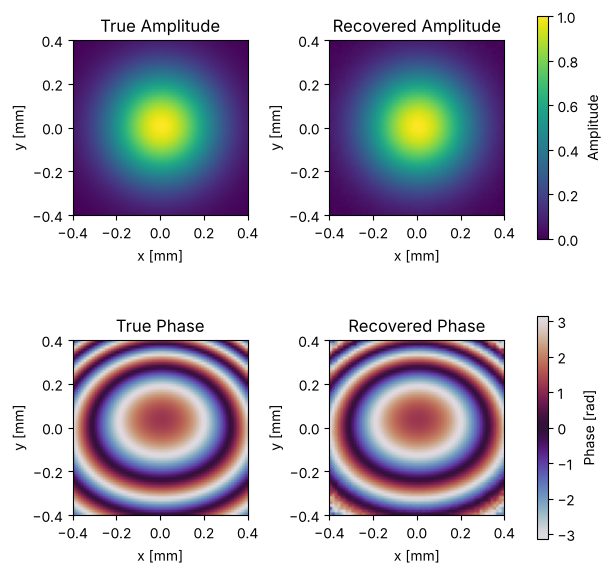

Total Runtime   (s): 10.61688977
Avg. Runtime    (s): 10.61688977
Avg. Runtime SI (s): 2.8728451919999998
Avg. Runtime W  (s): 7.744042097000005
Accuracy        (%): 0.9999584957450183
Phase RMS error    : 0.0064 rad = 0.00103 λ (λ/975)


In [6]:
for j in range(1):
    runtime = 0
    runtime_spec = 0
    runtime_Wirt = 0
    accuracy = 0
    phase_rms = 0
    runs = 1
    norm_x = np.sqrt(np.real(np.vdot(x, x)))

    for i in range(runs):
        rng_init = np.random.default_rng(seed + 1 + i)
        # Reconstruct with the masks the model believes the SLM produced.
        D_model = effective_masks(D, zero_order_power, zero_order_phase)
        X = reconstruct_x(y, D_model, prop_ideal, sampler_ideal, iter_WF, iter_SI, tol_WF, tol_SI, tau0, mu_max, True, sigma, dx_slm, rng_init)
        runtime += X[1][0]
        runtime_spec += X[1][1]
        runtime_Wirt += X[1][2]
        accuracy += np.abs(np.vdot(X[0], x)) / (np.sqrt(np.real(np.vdot(X[0], X[0]))) * norm_x)

        # Phase RMS error: remove the global phase, then weight each pixel by the true intensity.
        theta = np.angle(np.vdot(X[0], x))
        dphi = np.angle(X[0] * np.exp(1j * theta) * np.conj(x))
        w = np.abs(x) ** 2
        phase_rms += np.sqrt(np.sum(w * dphi ** 2) / np.sum(w))

    print(f"Total Runtime   (s): {runtime}")
    print(f"Avg. Runtime    (s): {runtime / runs}")
    print(f"Avg. Runtime SI (s): {runtime_spec / runs}")
    print(f"Avg. Runtime W  (s): {runtime_Wirt / runs}")
    print(f"Accuracy        (%): {accuracy / runs}")
    print(f"Phase RMS error    : {phase_rms / runs:.4f} rad = {phase_rms / runs / (2 * np.pi):.5f} λ "
          f"(λ/{2 * np.pi * runs / phase_rms:.0f})")

In [ ]:
from matplotlib.patches import Polygon

def visualize_sampling_2d(
    n_prop,
    dx_prop,
    n_det,
    dx_det,
    shift_x=0,
    shift_y=0,
    rotation_deg=0,
    step=16,
    origin=None,
    n_slm=None,
    tilt_x_deg=0,
    tilt_y_deg=0,
):
    """Plot the camera pixel positions over the propagation grid and the SLM aperture.

    Uses the same geometry as SamplingOperator: in-plane rotation, then tilt about x
    and y (projected onto the propagation plane), then shift.

    Parameters
    ----------
    n_prop, dx_prop : int, float
        Propagation grid size and pitch [m].
    n_det, dx_det : int, float
        Camera pixels per side and pitch [m].
    shift_x, shift_y : float
        Camera displacement from the optical axis [m].
    rotation_deg : float
        In-plane camera rotation [deg].
    step : int
        Plot every `step`-th pixel in each direction.
    origin : float, optional
        Grid index of the optical axis; default n_prop / 2.
    n_slm : int, optional
        SLM grid size; if given, the SLM aperture is drawn.
    tilt_x_deg, tilt_y_deg : float
        Out-of-plane camera tilt [deg].
    """

    if origin is None:
        origin = n_prop / 2

    x_min_prop = -origin * dx_prop
    width_prop = n_prop * dx_prop

    x_det = (np.arange(n_det) - n_det/2) * dx_det
    y_det = (np.arange(n_det) - n_det/2) * dx_det

    Xd, Yd = np.meshgrid(
        x_det,
        y_det,
        indexing="ij"
    )

    theta = np.deg2rad(rotation_deg)

    ct = np.cos(theta)
    st = np.sin(theta)

    tx, ty = np.deg2rad(tilt_x_deg), np.deg2rad(tilt_y_deg)
    X_r = ct * Xd - st * Yd
    Y_r = st * Xd + ct * Yd
    Xd_rot = X_r * np.cos(ty) + Y_r * np.sin(tx) * np.sin(ty) + shift_x
    Yd_rot = Y_r * np.cos(tx) + shift_y

    plt.figure(figsize=(8, 8))

    plt.gca().add_patch(
        plt.Rectangle(
            (x_min_prop, x_min_prop),
            width_prop,
            width_prop,
            fill=False,
            linewidth=3,
            color="blue",
            label="Propagation grid"
        )
    )

    if n_slm is not None:
        width_slm = n_slm * dx_prop
        plt.gca().add_patch(
            plt.Rectangle(
                (-width_slm/2, -width_slm/2),
                width_slm,
                width_slm,
                fill=False,
                linewidth=2,
                color="green",
                label="SLM aperture",
                zorder=3
            )
        )

    plt.scatter(
        Xd_rot[::step, ::step],
        Yd_rot[::step, ::step],
        s=8,
        color="red",
        label="Detector pixels"
    )

    plt.axis("equal")
    plt.grid(True)

    plt.xlabel("x [m]")
    plt.ylabel("y [m]")

    plt.legend()

    plt.title(
        f"dx_prop={dx_prop:.2e}, "
        f"dx_det={dx_det:.2e}"
    )

    plt.show()

In [ ]:
visualize_sampling_2d(
    n_prop=n_prop,
    dx_prop=dx_slm,
    n_det=n_cam,
    dx_det=dx_cam,
    shift_x=shift_x_true,
    shift_y=shift_y_true,
    rotation_deg=rotation_true,
    step = 1,
    origin=prop.origin,
    n_slm=n_slm,
    tilt_x_deg=tilt_x_true,
    tilt_y_deg=tilt_y_true
)

## Tolerance sweeps
Run the settings cell first, then any sweep cell on its own. Each sweep cell runs its simulations, plots them and prints the tolerance.

All sweep values and plots are in **real-setup units**. The simulation is a scale model (`SCALE` in the parameters cell); the settings cell converts rotation, tilt and wavelength errors to the scale model automatically. Shift, distance, noise, zeroth order, fill factor and aberrations carry over unchanged (checked at scales 8, 12 and 16).

In [ ]:
# ===================== TOLERANCE SWEEPS: SETTINGS AND HELPERS =====================
# Run this cell first (and again after changing the parameters cell); each sweep below is
# then a separate cell with its own plot. Every point is a full simulation: data from a
# "true" system with one error, reconstructed with the nominal system.

import os
import multiprocessing as mp

# ---- speed / accuracy settings ------------------------------------------------
QUICK = False                 # True: 1 seed and a looser stopping rule, ~3x faster (for a first look)

SWEEP = dict(
    n_seeds = 2,              # independent masks, noise and start per point (2 = see the spread)
    upsample = 2,             # keep 2: the Fourier upsampling is what makes the detector model accurate
    pixel_subsamples = 1,     # 1 instead of 2: ~2.5x faster; skips averaging over each pixel's area
    iter_WF = 1000,           # maximum iterations; runs stop by themselves once converged
    iter_SI = 300,            # spectral initialisation iterations (it usually stops earlier)
    mu_max = 0.2,             # normalised step size (stable for 10x brightness and fill factor 0.6 in tests)
    precision = "single",     # ~1.5x faster; results identical to double at the plotted accuracy
    tol_WF = 3e-4,            # looser than 1e-4: ~25 % fewer iterations, same tolerance results
    n_workers = 1 if GPU else os.cpu_count(),   # one process on the GPU: CUDA does not survive
                                                # forking, and the GPU does the parallel work
)
if QUICK:
    SWEEP.update(n_seeds=1, tol_WF=1e-3)
phase_rms_limit = 2 * np.pi / 20   # pass/fail line [rad]: lambda/20 rms (0.314 rad, ~32 nm OPD)
base_aberrations = {"defocus": 5, "astig_0": 2, "coma_x": 1}   # keep equal to the beam defined above

# Nominal system: what the reconstruction assumes (captured from the parameters cell).
NOMINAL = dict(wavelength=wavelength, z=z, shift_x=0.0, shift_y=0.0, rotation=0.0,
               tilt_x=0.0, tilt_y=0.0, fill_factor=fill_factor,
               zero_order_power=zero_order_power, zero_order_phase=zero_order_phase)

# ---- real setup <-> scale model ------------------------------------------------
# Shift and distance errors carry over unchanged; rotation, tilt and wavelength need the
# conversions below (checked against simulations at SCALE = 8, 12, 16).
def sim_rotation(deg_real):
    """Scale-model rotation [deg] that moves the camera-edge pixels as far as `deg_real`
    does on the real (SCALE times larger) camera."""
    return deg_real * SCALE

def sim_tilt(deg_real):
    """Scale-model tilt [deg] with the same edge foreshortening W/2 (1 - cos) as a real
    tilt of `deg_real`. Only foreshortening is matched; the change of distance across a
    tilted camera is not modelled."""
    return np.degrees(np.arccos(1 - SCALE * (1 - np.cos(np.radians(deg_real)))))

def sim_wavelength_error(dl_real):
    """Scale-model wavelength error [m] with the same effect as `dl_real` on the real setup
    (propagation depends on wavelength * z, and z is scaled down by SCALE)."""
    return dl_real * SCALE

def _build_system(p, n_p):
    """Propagator and SamplingOperator for the system described by dict `p` on an n_p grid."""
    pr = Propagator(n_slm, n_p, dx_slm, p["wavelength"], p["z"],
                    fill_factor=p["fill_factor"], upsample=SWEEP["upsample"], precision=SWEEP["precision"])
    sa = SamplingOperator(n_prop=pr.n_out, dx_prop=pr.dx_out, n_det=n_cam, dx_det=dx_cam,
                          shift_x=p["shift_x"], shift_y=p["shift_y"], rotation_deg=p["rotation"],
                          origin=pr.origin_out, tilt_x_deg=p["tilt_x"], tilt_y_deg=p["tilt_y"],
                          subsamples=SWEEP["pixel_subsamples"], precision=SWEEP["precision"])
    return pr, sa

def _aberration_basis(n, dx):
    """Low-order aberration terms on the n x n SLM grid, normalised as in `define_sample`."""
    R = n * dx / 2
    c = (np.arange(n) - n/2) * dx
    X, Y = np.meshgrid(c, c, indexing="ij")
    u, v = X / R, Y / R
    r2 = u**2 + v**2
    return {"piston": np.ones_like(u), "tilt_x": u, "tilt_y": v, "defocus": 2*r2 - 1,
            "astig_0": u**2 - v**2, "astig_45": 2*u*v, "coma_x": (3*r2 - 2)*u,
            "coma_y": (3*r2 - 2)*v, "spherical": 6*r2**2 - 6*r2 + 1}

def _metrics(xr, xt):
    """Compare a reconstruction `xr` with the true beam `xt`.

    Returns a dict with the relative error, the amplitude-weighted phase RMS error [rad]
    (after removing the global phase) and, as "bias_<term>", the aberration content of
    the phase error fitted with `_aberration_basis`.
    """
    xr = to_cpu(xr)
    th = np.angle(np.vdot(xr, xt))
    xa = xr * np.exp(1j * th)
    w = np.abs(xt) ** 2
    dphi = np.angle(xa * np.conj(xt))
    basis = _aberration_basis(xt.shape[0], dx_slm)
    A = np.stack([b.ravel() for b in basis.values()], 1)
    sw = np.sqrt(w.ravel())
    coef = np.linalg.lstsq(A * sw[:, None], dphi.ravel() * sw, rcond=None)[0]
    out = dict(rel_err=np.linalg.norm(xa - xt) / np.linalg.norm(xt),
               phase_rms=np.sqrt(np.sum(w * dphi**2) / np.sum(w)))
    out.update({"bias_" + k: c for k, c in zip(basis, coef) if k != "piston"})
    return out

def _solve(y, Dm, pr, sa, rng):
    """Spectral initialisation + Wirtinger Flow with the sweep settings; returns (x, iterations)."""
    x0 = spectral_init(y, Dm, pr, sa, SWEEP["iter_SI"], tol_SI, rng)
    return Wirtinger_iteration(x0, y, Dm, pr, sa, SWEEP["iter_WF"], SWEEP["tol_WF"], tau0, SWEEP["mu_max"],
                               return_iters=True)

def run_case(seed, true=None, model=None, aberrations=None, noise="default"):
    """Run one full simulation and return its metrics (see `_metrics`, plus "iters").

    Parameters
    ----------
    seed : int
        Seed for masks and noise; the start vector uses seed + 1000.
    true, model : dict, optional
        Entries overriding NOMINAL for the data-generating system and for the
        reconstruction model, respectively.
    aberrations : dict, optional
        Beam aberrations; default `base_aberrations`.
    noise : dict, None or "default"
        Camera-noise settings; "default" uses `camera_noise` if `use_noise` is set.
    """
    pt = {**NOMINAL, **(true or {})}
    pm = {**NOMINAL, **(model or {})}
    n_p = choose_prop_grid(n_slm, dx_slm, n_cam, dx_cam, max(pt["wavelength"], pm["wavelength"]),
                           max(pt["z"], pm["z"]),
                           shift_max=max(abs(pt["shift_x"]), abs(pt["shift_y"]), abs(pm["shift_x"]), abs(pm["shift_y"])),
                           rotation_max_deg=max(abs(pt["rotation"]), abs(pm["rotation"])), margin=1.0)
    pr_t, sa_t = _build_system(pt, n_p)
    pr_m, sa_m = _build_system(pm, n_p)

    xt = define_sample(n_slm, sigma, dx_slm, aberrations=base_aberrations if aberrations is None else aberrations)
    nz = (camera_noise if use_noise else None) if noise == "default" else noise

    # As generate_measurement, without its timing print.
    rng = np.random.default_rng(seed)
    D_prog = define_masks(L, n_slm, rng)
    y_meas = y_i(effective_masks(D_prog, pt["zero_order_power"], pt["zero_order_phase"]), xt, pr_t, sa_t)
    if nz is not None:
        y_meas = add_camera_noise(y_meas, rng, **nz)

    D_mod = effective_masks(D_prog, pm["zero_order_power"], pm["zero_order_phase"])
    xr, iters = _solve(y_meas, D_mod, pr_m, sa_m, np.random.default_rng(seed + 1000))
    m = _metrics(xr, xt)
    m["iters"] = iters
    return m

_SWEEP_CASES = []

def _sweep_job(args):
    """Worker task: run case `i` of the current sweep with seed offset `s`."""
    i, s = args
    try:
        pyfftw.config.NUM_THREADS = 1      # one FFT thread per process when running in parallel
    except NameError:
        pass
    return run_case(seed + s, **_SWEEP_CASES[i][2])

def run_sweep(cases):
    """Run every case for every seed, in parallel when possible.

    Parameters
    ----------
    cases : list of (label, x, kwargs)
        Curve label, x value, and keyword arguments for `run_case`.

    Returns
    -------
    dict
        {label: {"x": array, metric: array of shape (points, seeds)}}, sorted by x.
    """
    global _SWEEP_CASES
    _SWEEP_CASES = cases
    jobs = [(i, s) for i in range(len(cases)) for s in range(SWEEP["n_seeds"])]
    t0 = time.perf_counter()
    results = None
    if SWEEP["n_workers"] > 1:
        try:
            with mp.get_context("fork").Pool(SWEEP["n_workers"]) as pool:
                results = pool.map(_sweep_job, jobs)
        except (ValueError, OSError, RuntimeError) as err:
            print(f"parallel run unavailable ({err}); running sequentially")
    if results is None:
        results = [_sweep_job(j) for j in jobs]
    print(f"  {len(jobs)} simulations in {time.perf_counter() - t0:.0f} s")

    out = {}
    for (i, s), r in zip(jobs, results):
        label, xval, _ = cases[i]
        cur = out.setdefault(label, {})
        cur.setdefault(xval, []).append(r)
    curves = {}
    for label, pts in out.items():
        xs = sorted(pts)
        curves[label] = {"x": np.array(xs)}
        for key in pts[xs[0]][0]:
            curves[label][key] = np.array([[r[key] for r in pts[xv]] for xv in xs])
    return curves

def tolerance(xs, ys, limit=None):
    """Smallest x at which the curve ys(xs) crosses `limit` (default `phase_rms_limit`),
    by linear interpolation; inf if it never does. Failed (NaN) points count as failing."""
    limit = phase_rms_limit if limit is None else limit
    ys = np.nan_to_num(np.asarray(ys, dtype=float), nan=np.inf)
    for i in range(1, len(xs)):
        if ys[i] > limit >= ys[i - 1]:
            return xs[i-1] + (limit - ys[i-1]) * (xs[i] - xs[i-1]) / (ys[i] - ys[i-1])
        if ys[i] > limit:
            return xs[i]
    return np.inf

def plot_curves(ax, curves, xlabel, title, xscale=1.0, logx=False):
    """Draw the phase-RMS curves of a sweep on `ax`: mean over seeds with min-max error
    bars, the pass/fail limit and the perfect-system level. x values are multiplied by
    `xscale` for display."""
    for label, c in curves.items():
        mean = c["phase_rms"].mean(1)
        err = [mean - c["phase_rms"].min(1), c["phase_rms"].max(1) - mean]
        ax.errorbar(c["x"] * xscale, mean, yerr=err, marker="o", ms=4, capsize=3, label=label)
    ax.axhline(phase_rms_limit, color="k", ls="--", lw=1, label=f"limit λ/20 = {phase_rms_limit:.3f} rad")
    if "baseline" in globals():
        ax.axhline(BASELINE["phase_rms"].mean(), color="0.35", ls="-.", lw=1.4, label="perfect system")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("phase RMS error [rad]")
    ax.set_title(title)
    if logx:
        ax.set_xscale("log")
    ax.minorticks_on()
    ax.grid(which="major", alpha=0.35)
    ax.grid(which="minor", alpha=0.15, lw=0.5)
    ax.legend(fontsize=8)

def plot_sweep(curves, xlabel, title, xscale=1.0, logx=False):
    """New figure with `plot_curves` for one sweep; returns (fig, ax)."""
    fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
    plot_curves(ax, curves, xlabel, title, xscale=xscale, logx=logx)
    return fig, ax

def report(curves, unit, xscale=1.0, extra=None):
    """Print the tolerance of each curve in `unit` (x values times `xscale`).
    `extra(curve)` may return additional text for each line."""
    for label, c in curves.items():
        tol = tolerance(c["x"] * xscale, c["phase_rms"].mean(1))
        tol_txt = f"> {c['x'].max() * xscale:g} {unit} (never fails)" if np.isinf(tol) else f"{tol:.3g} {unit}"
        line = f"    {label:28s} tolerance: {tol_txt}"
        if extra:
            line += "   " + extra(c)
        print(line)
        convergence_check(label, c)

def convergence_check(label, c):
    """Warn about failed (NaN) runs, and about passing runs that hit the iteration limit
    (failing runs stay failing with more iterations, so only passing ones matter)."""
    if np.any(~np.isfinite(c["phase_rms"])):
        print(f"    WARNING: some '{label}' runs failed (NaN); they are counted as failing")
    capped = c["iters"] >= SWEEP["iter_WF"]
    if np.any(capped & (c["phase_rms"] < phase_rms_limit)):
        print(f"    WARNING: some passing '{label}' runs hit the {SWEEP['iter_WF']}-iteration limit; "
              f"increase SWEEP['iter_WF'] to check that tolerance")

def with_baseline(curves):
    """Prepend the perfect-system point (x = 0) to every curve; returns `curves`."""
    for c in curves.values():
        for key in c:
            if key == "x":
                c[key] = np.r_[0.0, c[key]]
            else:
                c[key] = np.vstack([BASELINE[key][None, :], c[key]])
    return curves

# ---- perfect system (shared x = 0 point) ------------------------------------
t_start = time.perf_counter()
print("Perfect system (baseline)")
baseline = run_sweep([("baseline", 0.0, {})])["baseline"]
BASELINE = {k: v[0] for k, v in baseline.items() if k != "x"}
print(f"    phase RMS {BASELINE['phase_rms'].mean():.3f} rad, rel err {BASELINE['rel_err'].mean():.3f}")
print(f"    {(time.perf_counter() - t_start):.0f} s for {SWEEP['n_seeds']} simulation(s); "
      f"each sweep cell below runs 8-24 points")

### 1) Lateral camera shift

In [ ]:
# ---- 1) Lateral camera shift (real units; carries over unchanged) -------------------
vals = [1e-6, 2e-6, 3e-6, 4e-6, 5e-6, 6e-6]
sweep_shift = with_baseline(run_sweep(
    [("shift x", v, dict(true=dict(shift_x=v))) for v in vals] +
    [("shift y", v, dict(true=dict(shift_y=v))) for v in vals]))

plot_sweep(sweep_shift, "camera shift [µm]", "1) Lateral camera shift", xscale=1e6)
plt.show()
report(sweep_shift, "µm", 1e6)

### 2) SLM–camera distance

In [ ]:
# ---- 2) SLM-camera distance (real units; carries over unchanged) --------------------
vals = [0.05e-3 * k for k in range(1, 13)]          # 0.05 ... 0.6 mm
sweep_z = with_baseline(run_sweep(
    [("camera farther (+dz)", v, dict(true=dict(z=z + v))) for v in vals] +
    [("camera closer (-dz)", v, dict(true=dict(z=z - v))) for v in vals]))

plot_sweep(sweep_z, "|distance error| [mm]", "2) SLM-camera distance", xscale=1e3)
plt.show()
report(sweep_z, "mm", 1e3)

### 5) In-plane rotation

In [ ]:
# ---- 5) In-plane rotation (real degrees, converted to the scale model) -------------
vals = [0.025, 0.05, 0.1, 0.15, 0.2, 0.3]
sweep_rot = with_baseline(run_sweep([("rotation", v, dict(true=dict(rotation=sim_rotation(v)))) for v in vals]))

plot_sweep(sweep_rot, "rotation [deg]", "5) In-plane rotation")
plt.show()
report(sweep_rot, "deg")

### 6) Camera tilt

In [ ]:
# ---- 6) Camera tilt (real degrees, converted to the scale model) -------------------
vals = [1.0, 2.0, 3.0, 4.0, 5.0, 6.0]
sweep_tilt = with_baseline(run_sweep(
    [("tilt about x", v, dict(true=dict(tilt_x=sim_tilt(v)))) for v in vals] +
    [("tilt about y", v, dict(true=dict(tilt_y=sim_tilt(v)))) for v in vals] +
    [("tilt about x and y", v, dict(true=dict(tilt_x=sim_tilt(v), tilt_y=sim_tilt(v)))) for v in vals]))

plot_sweep(sweep_tilt, "tilt [deg]", "6) Camera tilt")
plt.show()
report(sweep_tilt, "deg", extra=lambda c: "astigmatism bias at max tilt: "
       f"{c['bias_astig_0'][-1].mean():+.3f} rad (0 deg), {c['bias_astig_45'][-1].mean():+.3f} rad (45 deg)")

### 3) Zeroth-order leak

In [ ]:
# ---- 3) Zeroth-order leak -----------------------------------------------------
vals = [0.01, 0.02, 0.05, 0.10]
sweep_zo = with_baseline(run_sweep(
    [("model ignores it", v, dict(true=dict(zero_order_power=v), model=dict(zero_order_power=0.0))) for v in vals] +
    [("model knows it", v, dict(true=dict(zero_order_power=v), model=dict(zero_order_power=v))) for v in vals] +
    [("known power, phase off by 90°", v, dict(true=dict(zero_order_power=v, zero_order_phase=np.pi/2),
                                                model=dict(zero_order_power=v, zero_order_phase=0.0))) for v in vals]))

plot_sweep(sweep_zo, "unmodulated power [%]", "3) Zeroth-order leak", xscale=100)
plt.show()
report(sweep_zo, "% power", 100)

### 4) Noise / exposure

In [ ]:
# ---- 4) Noise / exposure --------------------------------------------------------
fills = [0.01, 0.03, 0.1, 0.3, 0.9]
noise_cases = []
for fw in [2000, 20000]:
    for pf in fills:
        nz = {**camera_noise, "full_well": fw, "peak_fill": pf}
        noise_cases.append((f"full well {fw} e-", pf * fw, dict(noise=nz)))   # x = electrons in the brightest pixel
sweep_noise = run_sweep(noise_cases)

plot_sweep(sweep_noise, "electrons in the brightest pixel", "4) Noise / exposure", logx=True)
plt.show()
print("    phase RMS by electrons in the brightest pixel")
for label, c in sweep_noise.items():
    print(f"      {label:18s} " + ", ".join(f"{x:g} e-: {p:.3f}" for x, p in zip(c["x"], c["phase_rms"].mean(1))))
    convergence_check(label, c)

### 7) Fill-factor mismatch

In [ ]:
# ---- 7) Fill-factor mismatch ------------------------------------------------------
vals = [0.80, 0.85, 0.90, 0.95, 1.00]
sweep_ff = run_sweep([(f"model assumes {fill_factor:g}", v, dict(true=dict(fill_factor=v))) for v in vals])

plot_sweep(sweep_ff, "true SLM fill factor", "7) Fill-factor mismatch")
plt.show()
for label, c in sweep_ff.items():
    print(f"    {label}: " + ", ".join(f"{x:.2f}: {p:.3f} rad" for x, p in zip(c["x"], c["phase_rms"].mean(1))))
    convergence_check(label, c)

### 8) Beam aberrations

In [ ]:
# ---- 8) Beam aberrations (one term changed at a time, others as in base_aberrations) ----
beam_cases = []
for term, values in [("defocus", [0, 15, 30]), ("astig_0", [0, 5, 10]), ("coma_x", [0, 5, 10])]:
    for v in values:
        beam_cases.append((term, float(v), dict(aberrations={**base_aberrations, term: v})))
sweep_beam = run_sweep(beam_cases)

def max_phase_step(ab):
    """Largest phase change between neighbouring SLM pixels [rad] for beam aberrations `ab`;
    it must stay well below pi for the SLM grid to represent the beam."""
    ph = np.angle(define_sample(n_slm, sigma, dx_slm, aberrations=ab))
    d = [np.angle(np.exp(1j * np.diff(ph, axis=a))) for a in (0, 1)]
    return max(np.abs(d[0]).max(), np.abs(d[1]).max())

plot_sweep(sweep_beam, "aberration coefficient [rad]", "8) Beam aberrations (one term varied)")
plt.show()
print("    phase RMS and largest phase step per SLM pixel (results are not meaningful above ~pi/2 per pixel)")
for term, c in sweep_beam.items():
    for x, p in zip(c["x"], c["phase_rms"].mean(1)):
        step = max_phase_step({**base_aberrations, term: x})
        flag = "  <-- over pi/2 per pixel" if step > np.pi / 2 else ""
        print(f"      {term:8s} = {x:4g} rad: phase RMS {p:.3f} rad, max step {step:.2f} rad/pixel{flag}")
    convergence_check(term, c)

### 9) Wavelength

In [ ]:
# ---- 9) Wavelength ---------------------------------------------------------------
vals = [-0.5e-9, -0.2e-9, 0.2e-9, 0.5e-9]
sweep_wl = run_sweep([("wavelength error", v, dict(true=dict(wavelength=wavelength + sim_wavelength_error(v))))
                      for v in vals])   # real Δλ, converted to the scale model
c = sweep_wl["wavelength error"]                  # insert the perfect system at 0 (middle of the curve)
i0 = np.searchsorted(c["x"], 0.0)
for key in list(c):
    c[key] = np.insert(c[key], i0, 0.0, axis=0) if key == "x" else np.insert(c[key], i0, BASELINE[key], axis=0)

fig, ax = plot_sweep(sweep_wl, "wavelength error [nm]", "9) Wavelength", xscale=1e9)
top = ax.secondary_xaxis("top", functions=(lambda d: d * 1e-9 / wavelength * z_real * 1e3,
                                           lambda dz: dz * 1e-3 / z_real * wavelength * 1e9))
top.set_xlabel("equivalent distance error z·Δλ/λ [mm]")
plt.show()
print("    " + ", ".join(f"{x*1e9:+.2f} nm: {p:.3f} rad" for x, p in zip(c["x"], c["phase_rms"].mean(1))))
convergence_check("wavelength error", c)